In [253]:
# Exploratory Data Analysis (EDA)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

sns.set(style="darkgrid")

# Load the cleaned dataset
data = pd.read_parquet(".cache/vehicles_cleaned.parquet")

In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   region        426880 non-null  str    
 1   price         426880 non-null  int64  
 2   year          425675 non-null  float64
 3   manufacturer  409234 non-null  str    
 4   model         421603 non-null  str    
 5   condition     252776 non-null  str    
 6   cylinders     249202 non-null  str    
 7   fuel          423867 non-null  str    
 8   odometer      422480 non-null  float64
 9   title_status  418638 non-null  str    
 10  transmission  424324 non-null  str    
 11  drive         296313 non-null  str    
 12  size          120519 non-null  str    
 13  type          334022 non-null  str    
 14  paint_color   296677 non-null  str    
 15  state         426880 non-null  str    
 16  lat           420331 non-null  float64
 17  long          420331 non-null  float64
dtypes: float64(4), 

In [255]:
data.describe()

,price,year,odometer,lat,long
count,4.268800e+05,425675.000000,4.224800e+05,420331.000000,420331.000000
mean,7.519903e+04,2011.235191,9.804333e+04,38.493940,-94.748599
std,1.218228e+07,9.452120,2.138815e+05,5.841533,18.365462
min,0.000000e+00,1900.000000,0.000000e+00,-84.122245,-159.827728
25%,5.900000e+03,2008.000000,3.770400e+04,34.601900,-111.939847
50%,1.395000e+04,2013.000000,8.554800e+04,39.150100,-88.432600
75%,2.648575e+04,2017.000000,1.335425e+05,42.398900,-80.832039
max,3.736929e+09,2022.000000,1.000000e+07,82.390818,173.885502


### Target analysis

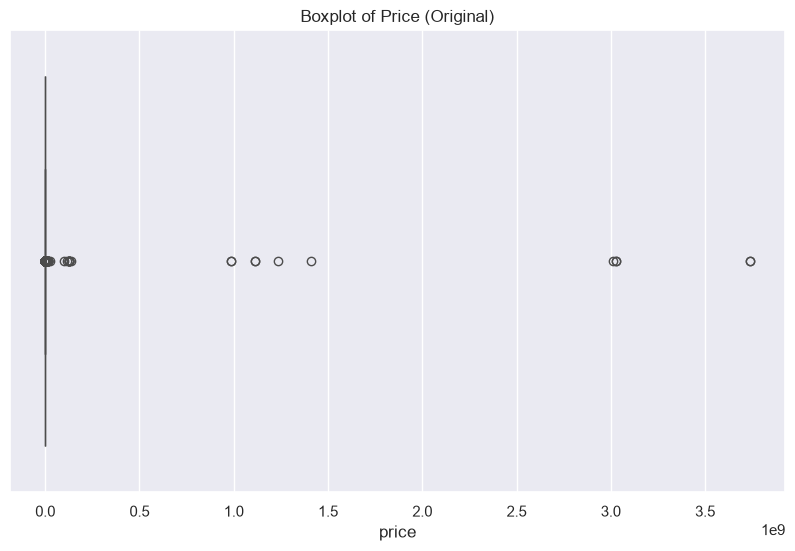

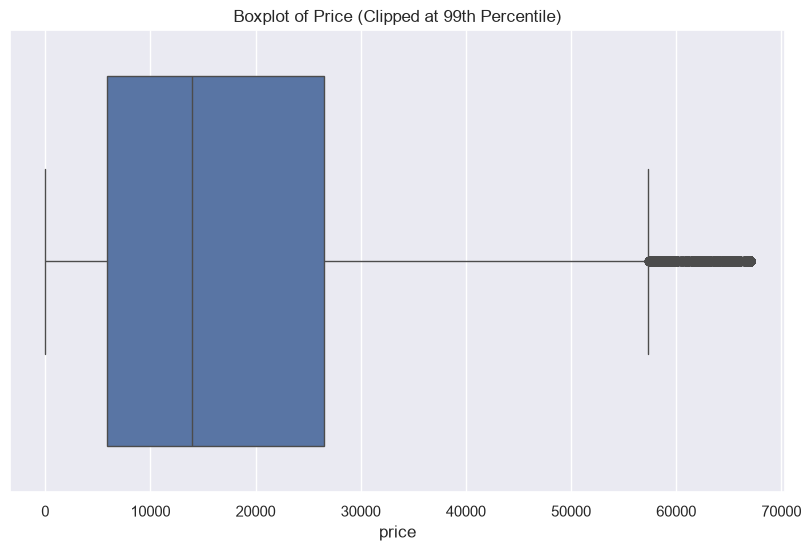

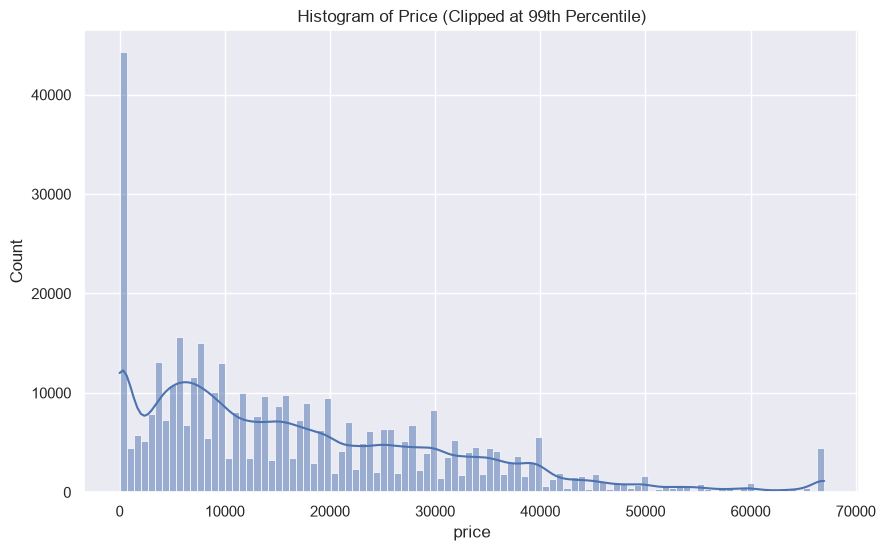

In [256]:
# Three visualizations for price: original and clipped at 99th percentile

plt.figure(figsize=(10, 6))
sns.boxplot(x=data["price"])
plt.title("Boxplot of Price (Original)")
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(x=data["price"].clip(upper=data["price"].quantile(0.99)))
plt.title("Boxplot of Price (Clipped at 99th Percentile)")
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(x=data["price"].clip(upper=data["price"].quantile(0.99)), kde=True, bins=100)
plt.title("Histogram of Price (Clipped at 99th Percentile)")
plt.show()

In [257]:
# Percentage of cars priced 0
zero_price_percentage = (data["price"] == 0).mean() * 100
print(f"Percentage of cars priced 0: {zero_price_percentage:.2f}%")

Percentage of cars priced 0: 7.71%


In [258]:
# Percentage of cars priced between 0 and 1000
percentage_cars_0_1000 = ((data['price'] >= 0) & (data['price'] <= 1000)).mean() * 100
print(f"Percentage of cars priced between 0 and 1000: {percentage_cars_0_1000:.2f}%")

Percentage of cars priced between 0 and 1000: 11.13%


#### Notes:  
        - big outliers in the 99th percentile
        - distribution skewed to the right
        - 7.71% of cars priced at 0$
        - 11.13% percent priced between 0$ and 1000$

In [259]:
data.columns

Index(['region', 'price', 'year', 'manufacturer', 'model', 'condition',
       'cylinders', 'fuel', 'odometer', 'title_status', 'transmission',
       'drive', 'size', 'type', 'paint_color', 'state', 'lat', 'long'],
      dtype='str')

## Numeric features analysis: year, odometer, lat, long

### Year

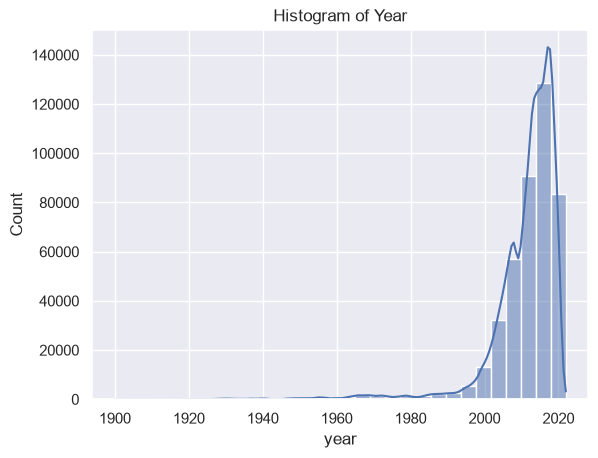

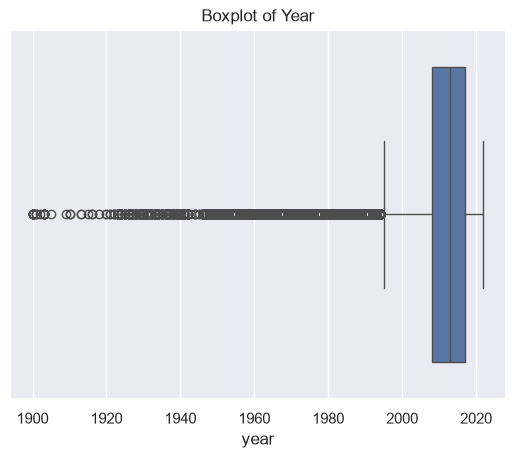

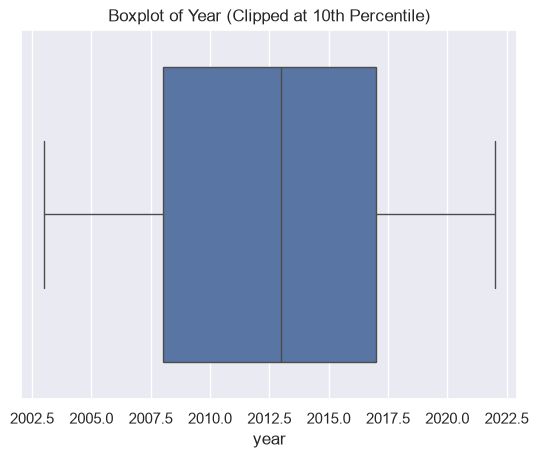

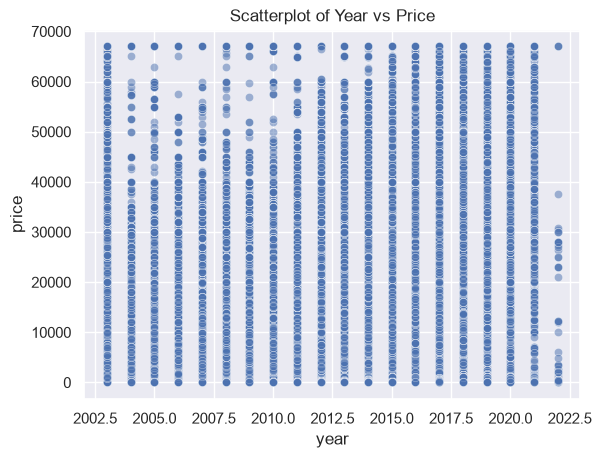

In [260]:
# Make a histplot and a boxplot of the year column, a boxplot clipped at the 10th percentile, and a scatterplot of year vs price

sns.histplot(x=data["year"], kde=True, bins=30)
plt.title("Histogram of Year")
plt.show()

sns.boxplot(x=data["year"])
plt.title("Boxplot of Year")
plt.show()

sns.boxplot(x=data["year"].clip(lower=data["year"].quantile(0.1)))
plt.title("Boxplot of Year (Clipped at 10th Percentile)")
plt.show()

sns.scatterplot(data = data.sample(frac=0.01, random_state=42), x=data["year"].clip(lower=data["year"].quantile(0.1)), y=data["price"].clip(upper=data["price"].quantile(0.99)), 
                alpha=0.5)
plt.title("Scatterplot of Year vs Price")
plt.show()

In [261]:
# Average price of cars per decade between 1900 and 2000, for all cars, and add a column for the count of cars per decade
decades = range(1900, 2010, 10)
average_price_per_decade = {}
count_per_decade = {}
for decade_start in decades:
    decade_end = decade_start + 9
    decade_data = data[(data['year'] >= decade_start) & (data['year'] <= decade_end)]
    average_price_per_decade[f'{decade_start}s'] = decade_data['price'].mean()
    count_per_decade[f'{decade_start}s'] = decade_data.shape[0]

average_price_per_decade_table = pd.DataFrame({
    'decade': list(average_price_per_decade.keys()),
    'average_price': list(average_price_per_decade.values()),
    'count': list(count_per_decade.values())
})
average_price_per_decade_table

,decade,average_price,count
0,1900s,57361.166667,30
1,1910s,25625.000000,8
2,1920s,17409.014423,208
3,1930s,25064.195833,480
4,1940s,17622.501027,487
5,1950s,31024.199197,1245
6,1960s,767663.769830,2824
7,1970s,14763.259981,3131
8,1980s,393731.531234,3970
9,1990s,414082.547991,12867


#### Notes:

        - heavy left skew
        - lots of outliers in the 1900-2000 range (up to ~10th percentile)
        - relatively weak relationship with price
        - useful for creating 'age' column
        - best to drop all the cars up to year 2000

### Odometer

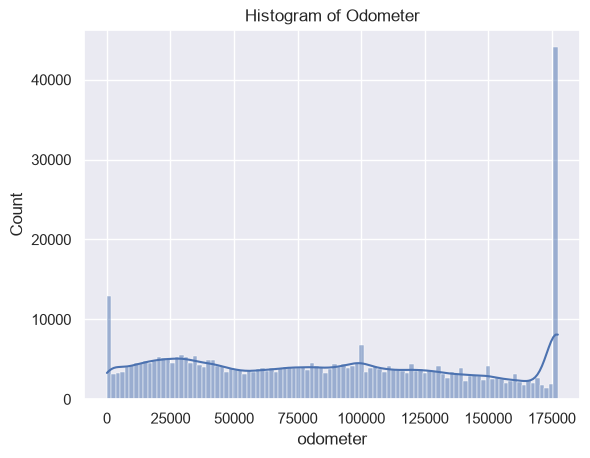

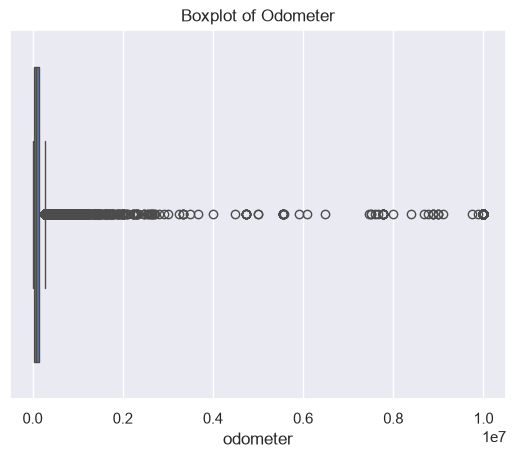

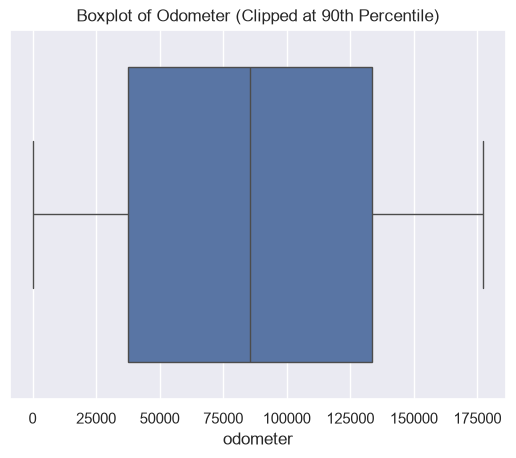

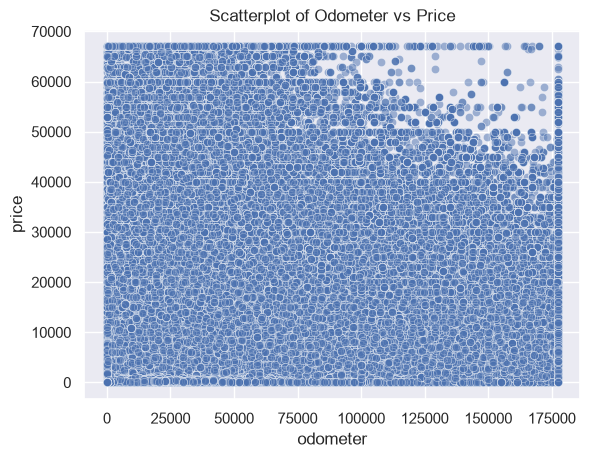

In [262]:
# Make a histplot and a boxplot of the odometer column and a scatterplot of odometer vs price

sns.histplot(x=data["odometer"].clip(upper=data["odometer"].quantile(0.90)), kde=True, bins=100)
plt.title("Histogram of Odometer")
plt.show()

sns.boxplot(x=data["odometer"])
plt.title("Boxplot of Odometer")
plt.show()

sns.boxplot(x=data["odometer"].clip(upper=data["odometer"].quantile(0.90)))
plt.title("Boxplot of Odometer (Clipped at 90th Percentile)")
plt.show()

sns.scatterplot(data = data.sample(frac=0.001, random_state=42), x=data["odometer"].clip(upper=data["odometer"].quantile(0.90)), y=data["price"].clip(upper=data["price"].quantile(0.99)), 
                alpha=0.5)
plt.title("Scatterplot of Odometer vs Price")
plt.show()

In [263]:
# Average odometer per decade between 1900 and 2000, for all cars, and add a column for the count of cars per decade
average_odometer_per_decade = {}
count_per_decade = {}
for decade_start in decades:
    decade_end = decade_start + 9
    decade_data = data[(data['year'] >= decade_start) & (data['year'] <= decade_end)]
    average_odometer_per_decade[f'{decade_start}s'] = decade_data['odometer'].mean()
    count_per_decade[f'{decade_start}s'] = decade_data.shape[0]

average_odometer_per_decade_table = pd.DataFrame({
    'decade': list(average_odometer_per_decade.keys()),
    'average_odometer': list(average_odometer_per_decade.values()),
    'count': list(count_per_decade.values())
})
average_odometer_per_decade_table

,decade,average_odometer,count
0,1900s,2.103207e+05,30
1,1910s,1.263075e+06,8
2,1920s,1.933889e+05,208
3,1930s,1.082546e+05,480
4,1940s,2.151295e+05,487
5,1950s,2.011773e+05,1245
6,1960s,1.282037e+05,2824
7,1970s,1.639052e+05,3131
8,1980s,1.465003e+05,3970
9,1990s,1.716376e+05,12867


#### Notes:
    
        - lots of outliers, probably best to clip at the 90th percentile, or around 500.000 to 1.000.000 miles
        - strong relationship to price
        - futher proof that it is best to drop all cars before year 2000

### Latitude and longitude

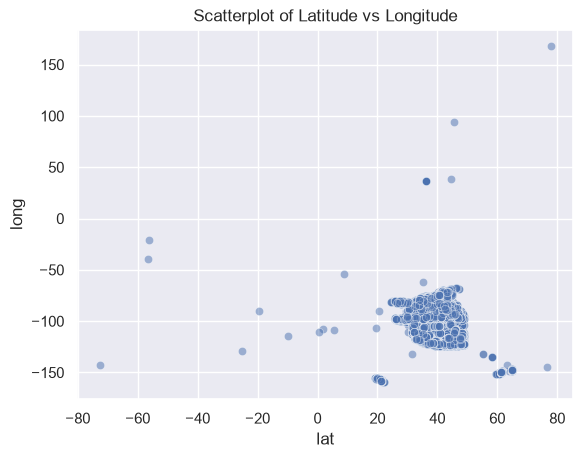

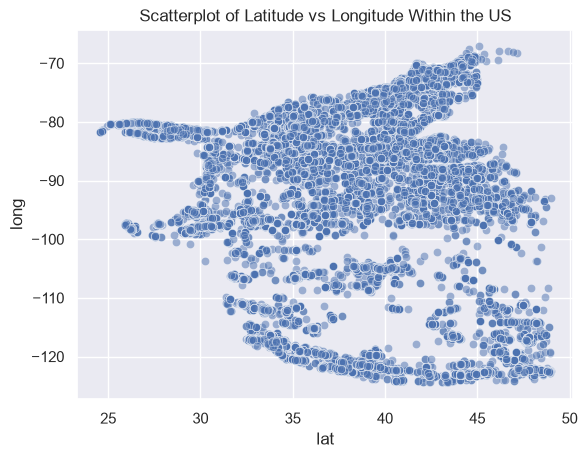

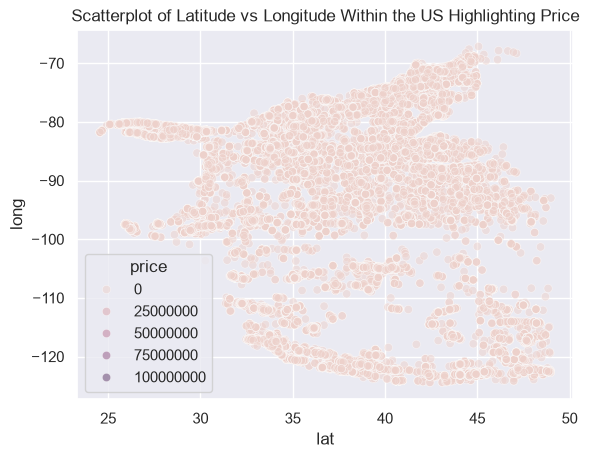

In [264]:
# Make a scatterplot of latitude vs longitude

sns.scatterplot(data=data.sample(frac=0.2, random_state=42), x="lat", y="long", alpha=0.5)
plt.title("Scatterplot of Latitude vs Longitude")
plt.show()

# Make a scatterplot of latitude vs longitude within the US

sns.scatterplot(data = data.loc[(data["lat"] >= 24.396308) & (data["lat"] <= 49.384358) & 
                                (data["long"] >= -125.0) & (data["long"] <= -66.93457)].sample(frac=0.2, random_state=42), x="lat", y="long", 
                alpha=0.5)
plt.title("Scatterplot of Latitude vs Longitude Within the US")
plt.show()

# Make a scatterplot of latitude vs longitude within the US highlighting price
sns.scatterplot(data = data.loc[(data["lat"] >= 24.396308) & (data["lat"] <= 49.384358) & 
                                (data["long"] >= -125.0) & (data["long"] <= -66.93457)].sample(frac=0.2, random_state=42), x="lat", y="long", hue="price", alpha=0.5)
plt.title("Scatterplot of Latitude vs Longitude Within the US Highlighting Price")
plt.show()

#### Notes:

        - keep it within the US
        - good idea to create clusters, could provide useful info

### Correlation between numeric features

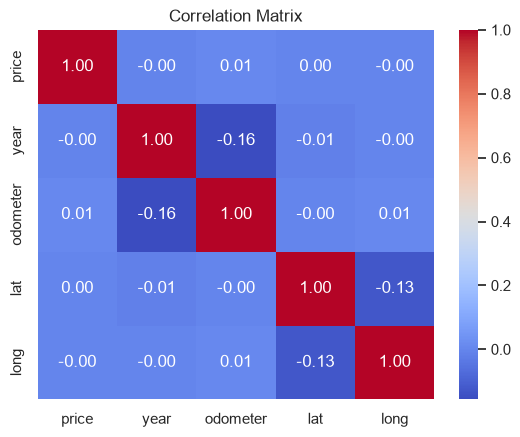

In [265]:
corr = data.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [266]:
data.columns

Index(['region', 'price', 'year', 'manufacturer', 'model', 'condition',
       'cylinders', 'fuel', 'odometer', 'title_status', 'transmission',
       'drive', 'size', 'type', 'paint_color', 'state', 'lat', 'long'],
      dtype='str')

## Categorical features analysis: region, manufacturer, model, condition, cylinders, fuel, title_status, transmission, drive, size, type, paint_color, state

In [267]:
def price_filtered(df):
    return df[(df['price'] > 0) & (df['price'] <= df['price'].quantile(0.99))]

### Region

In [268]:
# Make a table of average and median price per region sorted by price, and also add a column for the number of cars per region, removing outliers above the 99th percentile and cars priced 0$, but for the price column, not the average price

avg_price_per_region = price_filtered(data).groupby('region')['price'].mean().reset_index()
median_price_per_region = price_filtered(data).groupby('region')['price'].median().reset_index()
avg_price_per_region['median_price'] = median_price_per_region['price']
avg_price_per_region['num_cars'] = price_filtered(data).groupby('region')['price'].count().values
avg_price_per_region = avg_price_per_region.sort_values(by='price', ascending=False)
avg_price_per_region


,region,price,median_price,num_cars
310,scottsbluff / panhandle,31256.423423,32900.0,111
255,olympic peninsula,30873.722059,30999.0,680
34,boone,30819.607595,32445.5,316
336,southwest TX,30607.166667,30495.0,30
195,logan,30212.898551,33443.5,138
...,...,...,...,...
314,show low,10634.486486,7995.0,111
169,kenosha-racine,10583.218833,4299.5,754
327,southeast KS,10260.024390,7900.0,82
384,west virginia (old),9423.750000,9100.0,8


#### Notes:
        
        - ~400 regions total
        - there is clear relationship, but regions with low car number should be grouped

### Manufacturer

In [269]:
data['manufacturer'].nunique()

42

In [270]:
# Average and median price per manufacturer, with the number of cars per manufacturer, removing outliers above the 99th percentile and cars priced 0$, but for the price column, not the average price

avg_price_per_manufacturer = price_filtered(data).groupby('manufacturer')['price'].mean().reset_index()
median_price_per_manufacturer = price_filtered(data).groupby('manufacturer')['price'].median().reset_index()
avg_price_per_manufacturer['median_price'] = median_price_per_manufacturer['price']
avg_price_per_manufacturer['num_cars'] = price_filtered(data).groupby('manufacturer')['price'].count().values
avg_price_per_manufacturer = avg_price_per_manufacturer.sort_values(by='price', ascending=False)
avg_price_per_manufacturer

,manufacturer,price,median_price,num_cars
38,tesla,37672.761671,37990.0,814
1,alfa-romeo,29113.680460,29590.0,870
34,ram,28983.995917,29764.0,16163
2,aston-martin,27834.818182,37000.0,11
33,porsche,27527.155574,27990.0,1202
19,jaguar,26879.123353,28590.0,1897
35,rover,25886.337197,24990.0,1898
3,audi,24193.289548,24461.0,7118
14,gmc,23772.390889,22998.0,15081
18,infiniti,20999.106264,20999.0,4470


#### Notes:

        - consider grouping low-count manufacturers into other category, or just drop them
        - good relation to price

### Model

In [271]:
data['model'].value_counts()

model
f-150                      8009
silverado 1500             5140
1500                       4211
camry                      3135
silverado                  3023
                           ... 
rx& gls sport                 1
ATI                           1
gand wagoneer                 1
96 Suburban                   1
Paige Glenbrook Touring       1
Name: count, Length: 29667, dtype: int64

In [272]:
data['model'].nunique()

29667

In [273]:
# Average and median price per model, with the number of cars per model, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per model


average_price_per_model = price_filtered(data).groupby('model')['price'].mean()
median_price_per_model = price_filtered(data).groupby('model')['price'].median()
count_per_model = price_filtered(data).groupby('model')['price'].count()

price_per_model_table = pd.DataFrame({
    'average_price': average_price_per_model,
    'median_price': median_price_per_model,
    'count': count_per_model
}).sort_values(by='average_price', ascending=False)
price_per_model_table

,average_price,median_price,count
model,,,
2500 6.7 cummins diesel 4x4 laramie lifted on 37s,66995.000000,66995.0,2
aviator reserve,66988.000000,66988.0,1
grand cherokee srt awd,66950.000000,66950.0,1
2500hd sierra denali duramax,66900.000000,66900.0,1
model x 90d sport utility,66797.333333,66990.0,15
...,...,...,...
325i e30,1.000000,1.0,1
/ bertone x1/9,1.000000,1.0,1
All Makes & Models,1.000000,1.0,1


#### Notes:

        - high cardinality, ~30,000 unique models, probably best to drop 

### Condition

In [274]:
data['condition'].value_counts()

condition
good         121456
excellent    101467
like new      21178
fair           6769
new            1305
salvage         601
Name: count, dtype: int64

In [275]:
# Average price per condition, with the number of cars per condition, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per condition


average_price_per_condition = price_filtered(data).groupby('condition')['price'].mean()
median_price_per_condition = price_filtered(data).groupby('condition')['price'].median()
count_per_condition = price_filtered(data).groupby('condition')['price'].count()

price_per_condition_table = pd.DataFrame({
    'average_price': average_price_per_condition,
    'median_price': median_price_per_condition,
    'count': count_per_condition
}).sort_values(by='average_price', ascending=False)
price_per_condition_table

,average_price,median_price,count
condition,,,
new,21298.380309,17850.0,1036
good,20878.393817,20590.0,118974
like new,18001.203807,14500.0,19700
excellent,14914.689226,11900.0,94152
fair,3953.171233,2800.0,6716
salvage,3641.892437,1800.0,595


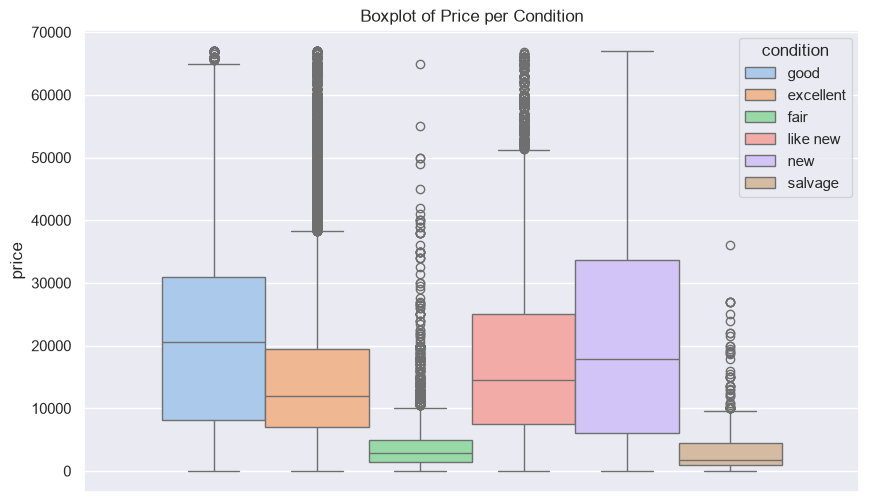

In [276]:
# Boxplot of price per condition, removing outliers above the 99th percentile and cars priced 0$
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(hue='condition', y='price', data=price_filtered(data), palette='pastel')
plt.title('Boxplot of Price per Condition')
plt.show()

#### Notes:

        - useful, noticeable difference across conditions in price
        - numerical imbalance between categories
        - has 40% null values, important to note

### Cylinders

In [277]:
# Average price per cylinder, with the number of cars per cylinder, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per cylinder


average_price_per_cylinder = price_filtered(data).groupby('cylinders')['price'].mean()
median_price_per_cylinder = price_filtered(data).groupby('cylinders')['price'].median()
count_per_cylinder = price_filtered(data).groupby('cylinders')['price'].count()

price_per_cylinder_table = pd.DataFrame({
    'average_price': average_price_per_cylinder,
    'median_price': median_price_per_cylinder,
    'count': count_per_cylinder
}).sort_values(by='average_price', ascending=False)
price_per_cylinder_table

,average_price,median_price,count
cylinders,,,
12 cylinders,24029.820513,20000.0,156
8 cylinders,22476.115577,19997.0,65238
other,18749.058040,12999.0,1051
6 cylinders,18109.080530,14998.0,88352
10 cylinders,17481.227477,14995.0,1332
3 cylinders,12442.574013,9995.0,608
4 cylinders,11059.851045,8995.0,72975
5 cylinders,7679.595081,6495.0,1667


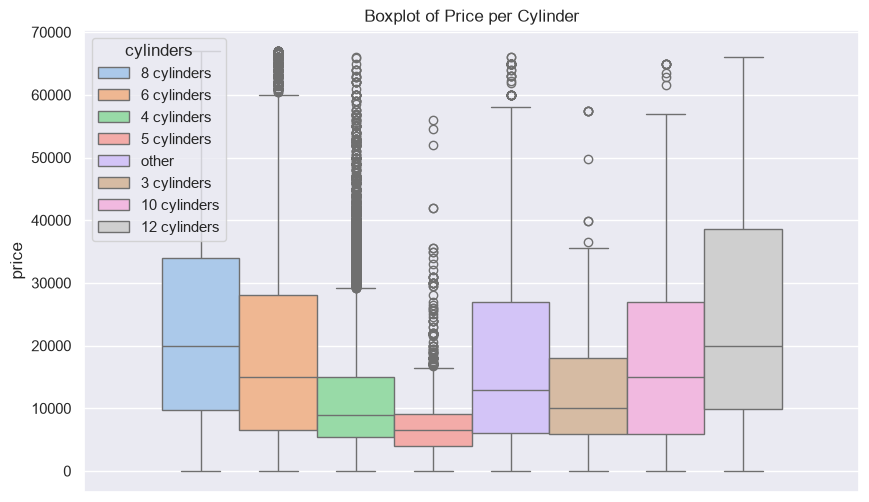

In [278]:
# Boxplot of price per cylinder, removing outliers above the 99th percentile and cars priced 0$
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(hue='cylinders', y='price', data=price_filtered(data), palette='pastel')
plt.title('Boxplot of Price per Cylinder')
plt.show()

#### Notes:

        - big imbalance between classes, but useful
        - has 41% null values, important

### Fuel

In [279]:
# Average price per fuel, with the number of cars per fuel, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per fuel

average_price_per_fuel = price_filtered(data).groupby('fuel')['price'].mean()
median_price_per_fuel = price_filtered(data).groupby('fuel')['price'].median()
count_per_fuel = price_filtered(data).groupby('fuel')['price'].count()

price_per_fuel_table = pd.DataFrame({
    'average_price': average_price_per_fuel,
    'median_price': median_price_per_fuel,
    'count': count_per_fuel
}).sort_values(by='average_price', ascending=False)
price_per_fuel_table

,average_price,median_price,count
fuel,,,
diesel,30419.623164,29990.0,24512
other,27020.234247,27590.0,27693
electric,24459.341724,23500.0,1589
gas,16515.973566,13460.0,328480
hybrid,15320.483190,12900.0,4878


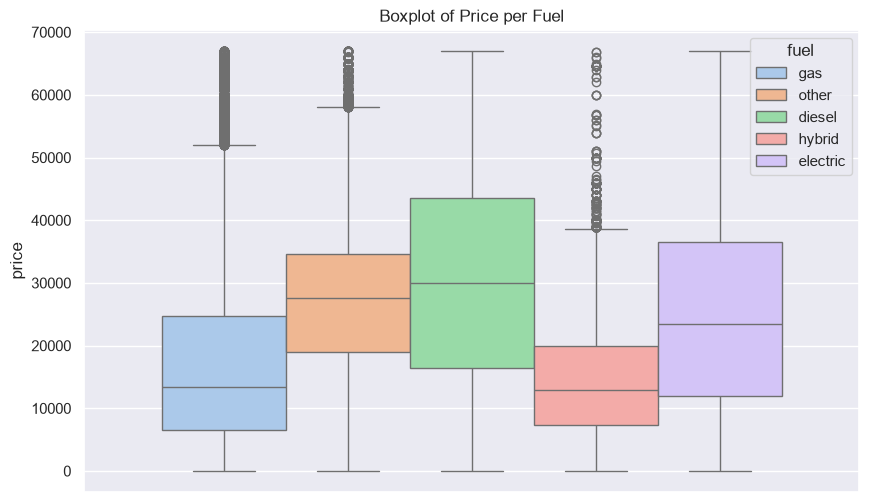

In [280]:
# Boxplot of price per fuel, removing outliers above the 99th percentile and cars priced 0$
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(hue='fuel', y='price', data=price_filtered(data), palette='pastel')
plt.title('Boxplot of Price per Fuel')
plt.show()

#### Notes:

        - gas is by far the most numerous category
        - useful

### Title-status

In [281]:
# Average price per title-status, with the number of cars per title-status, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per title-status

average_price_per_title_status = price_filtered(data).groupby('title_status')['price'].mean().sort_values()
count_per_title_status = price_filtered(data).groupby('title_status').size()
average_price_per_title_status_table = pd.DataFrame({
    'title_status': average_price_per_title_status.index,
    'average_price': average_price_per_title_status.values,
    'count': count_per_title_status.values
})
average_price_per_title_status_table

,title_status,average_price,count
0,parts only,3250.143617,368782
1,missing,4993.196178,1394
2,salvage,9461.959969,785
3,rebuilt,12715.085486,188
4,clean,18468.148497,7124
5,lien,20848.550215,3822


#### Notes:

        - huge imbalance in classes, plus there's data leakage for lien (implies a price for 
        an already sold car), best to drop

### Transmission

In [282]:
# Average price per transmission, with the number of cars per transmission, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per transmission

average_price_per_transmission = price_filtered(data).groupby('transmission')['price'].mean().sort_values()
count_per_transmission = price_filtered(data).groupby('transmission').size()
average_price_per_transmission_table = pd.DataFrame({
    'transmission': average_price_per_transmission.index,
    'average_price': average_price_per_transmission.values,
    'count': count_per_transmission.values
})
average_price_per_transmission_table

,transmission,average_price,count
0,manual,13834.124159,303044
1,automatic,16533.810473,23494
2,other,27925.857276,61384


C:\Users\Luka\AppData\Local\Temp\ipykernel_19512\3490375499.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='transmission', y='price', data=price_filtered(data), palette='pastel')


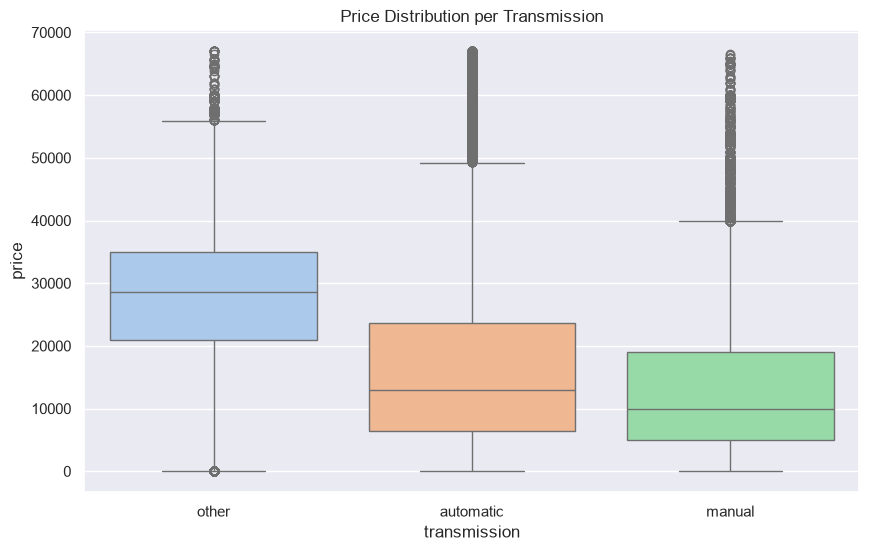

In [283]:
# Box plot of price distribution per transmission, removing outliers above the 99th percentile and cars priced 0$

plt.figure(figsize=(10, 6))
sns.boxplot(x='transmission', y='price', data=price_filtered(data), palette='pastel')
plt.title('Price Distribution per Transmission')
plt.show()

#### Notes:

        - manual is by far the largest category so some balancing will be necessary, seems useful

### Drive

In [284]:
# # Average price per drive, with the number of cars per drive, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per drive

average_price_per_drive = price_filtered(data).groupby('drive')['price'].mean().sort_values()
count_per_drive = price_filtered(data).groupby('drive').size()
average_price_per_drive_table = pd.DataFrame({
    'drive': average_price_per_drive.index,
    'average_price': average_price_per_drive.values,
    'count': count_per_drive.values
})
average_price_per_drive_table

,drive,average_price,count
0,fwd,12487.795050,118223
1,rwd,20111.840738,97497
2,4wd,22277.352723,54652


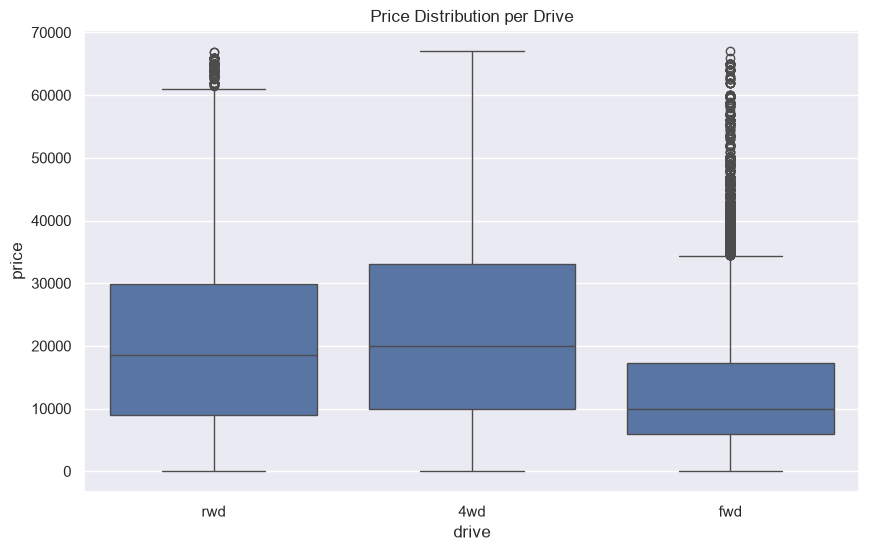

In [285]:
# Box plot of price distribution per drive, removing outliers above the 99th percentile and cars priced 0$

plt.figure(figsize=(10, 6))
sns.boxplot(x='drive', y='price', data=price_filtered(data))
plt.title('Price Distribution per Drive')
plt.show()

#### Notes:

        - seems relatively flat across categories
        - relatively balanced
        - seems moderately useful
        - 30% null values

### Size

In [286]:
# Average price per size, with the number of cars per size, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per size

average_price_per_size = price_filtered(data).groupby('size')['price'].mean().sort_values()
count_per_size = price_filtered(data).groupby('size').size()
average_price_per_size_table = pd.DataFrame({
    'size': average_price_per_size.index,
    'average_price': average_price_per_size.values,
    'count': count_per_size.values
})
average_price_per_size_table

,size,average_price,count
0,compact,11305.093399,17559
1,mid-size,12069.747234,58023
2,sub-compact,12224.516287,31820
3,full-size,16007.791721,2855


C:\Users\Luka\AppData\Local\Temp\ipykernel_19512\1772553351.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='size', y='price', data=price_filtered(data), palette='pastel')


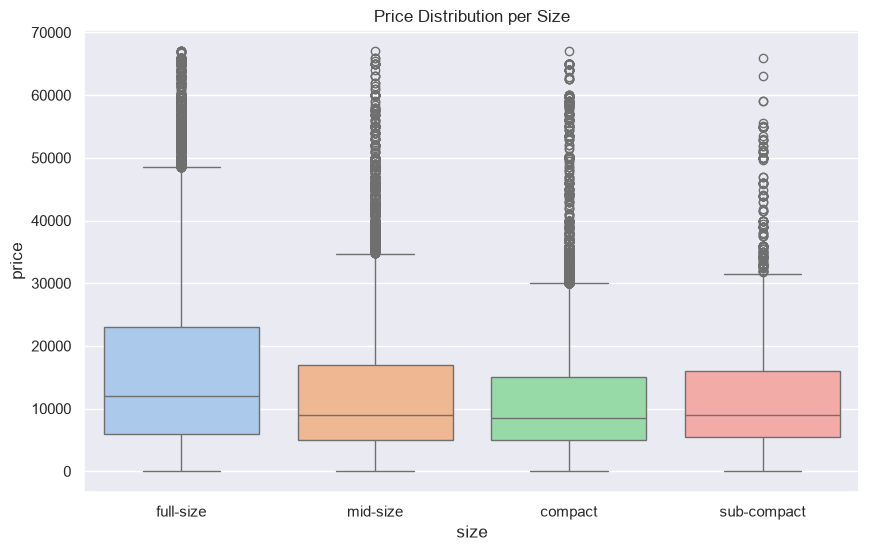

In [287]:
# Box plot of price distribution per size, removing outliers above the 99th percentile and cars priced 0$

plt.figure(figsize=(10, 6))
sns.boxplot(x='size', y='price', data=price_filtered(data), palette='pastel')
plt.title('Price Distribution per Size')
plt.show()

#### Notes:

        - almost no difference across categories
        - 70% null values
        - best to drop

### Type

In [288]:
# # Average price per type, with the number of cars per type, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per type

average_price_per_type = price_filtered(data).groupby('type')['price'].mean().sort_values()
count_per_type = price_filtered(data).groupby('type').size()
average_price_per_type_table = pd.DataFrame({
    'type': average_price_per_type.index,
    'average_price': average_price_per_type.values,
    'count': count_per_type.values
})
average_price_per_type_table

,type,average_price,count
0,mini-van,9713.850451,70186
1,sedan,14004.108923,497
2,wagon,14010.672639,7174
3,bus,14262.784708,17794
4,hatchback,14965.539695,15909
5,offroad,15985.065990,4547
6,SUV,17181.241872,591
7,convertible,17975.106635,19642
8,van,18164.206888,40585
9,coupe,21054.369619,80167


C:\Users\Luka\AppData\Local\Temp\ipykernel_19512\3963650545.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='type', y='price', data=price_filtered(data), palette='pastel')


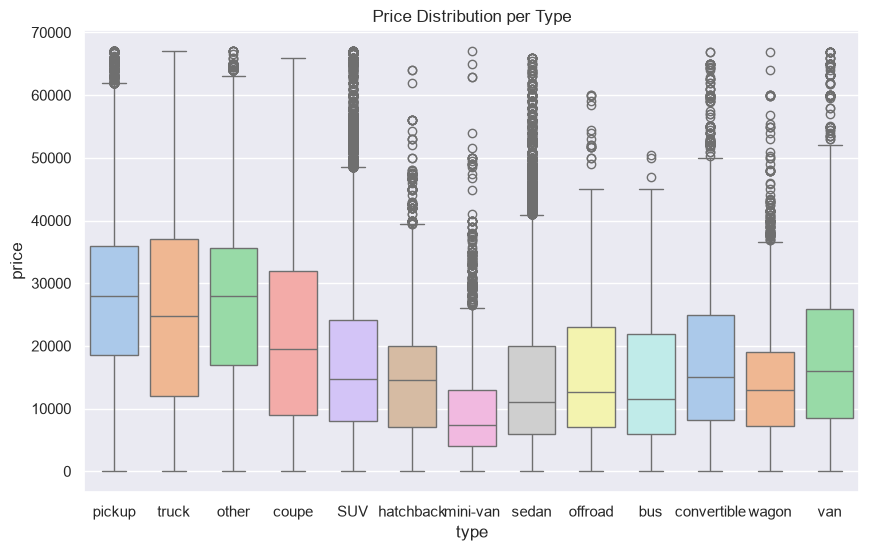

In [289]:
# Box plot of price distribution per type, removing outliers above the 99th percentile and cars priced 0$

plt.figure(figsize=(10, 6))
sns.boxplot(x='type', y='price', data=price_filtered(data), palette='pastel')
plt.title('Price Distribution per Type')
plt.show()

#### Notes:

        - seems useful
        - 20% null values
        - large imbalance between classes, maybe grouping smaller categories into 'other'

### Paint-color

In [290]:
# # Average price per paint-color, with the number of cars per paint-color, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per paint-color

average_price_per_paint_color = price_filtered(data).groupby('paint_color')['price'].mean().sort_values()
count_per_paint_color = price_filtered(data).groupby('paint_color').size()
average_price_per_paint_color_table = pd.DataFrame({
    'paint_color': average_price_per_paint_color.index,
    'average_price': average_price_per_paint_color.values,
    'count': count_per_paint_color.values
})
average_price_per_paint_color_table

,paint_color,average_price,count
0,green,12770.812163,57654
1,purple,14413.747384,29248
2,grey,14938.116577,6163
3,custom,15585.921445,6365
4,brown,15899.452539,7038
5,silver,16491.765222,22586
6,blue,16666.173482,1836
7,yellow,17611.170756,669
8,orange,18617.718410,28538
9,red,18834.803665,39893


C:\Users\Luka\AppData\Local\Temp\ipykernel_19512\3434262205.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='paint_color', y='price', data=price_filtered(data), palette='pastel')


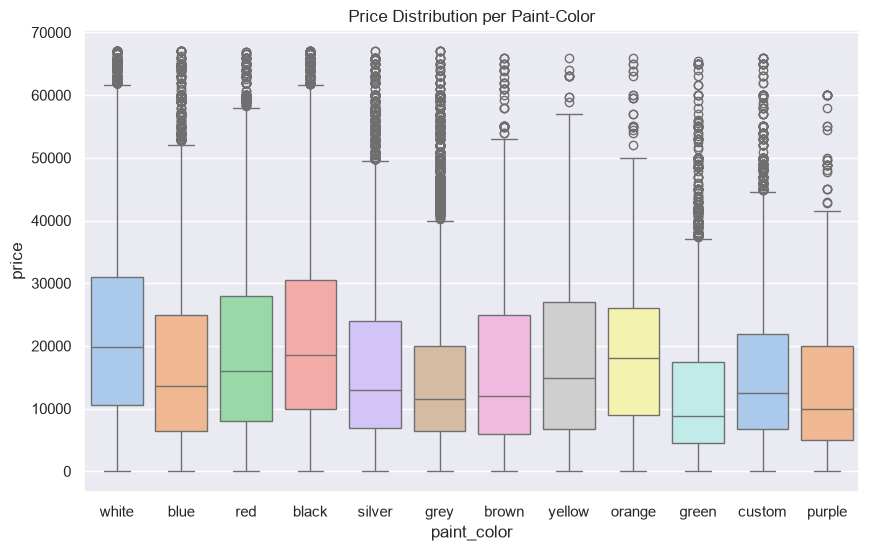

In [291]:
# Box plot of price distribution per paint-color, removing outliers above the 99th percentile and cars priced 0$

plt.figure(figsize=(10, 6))
sns.boxplot(x='paint_color', y='price', data=price_filtered(data), palette='pastel')
plt.title('Price Distribution per Paint-Color')
plt.show()

#### Notes:

        - 30% null values
        - very flat across paint colors, best to drop

### State

In [292]:
# Average price per state, with the number of cars per state, 
# removing outliers above the 99th percentile and cars priced 0$, 
# but for the price column, not the average price, ordered by the average price per state

average_price_per_state = price_filtered(data).groupby('state')['price'].mean().sort_values()
count_per_state = price_filtered(data).groupby('state').size()
average_price_per_state_table = pd.DataFrame({
    'state': average_price_per_state.index,
    'average_price': average_price_per_state.values,
    'count': count_per_state.values
})
average_price_per_state_table

,state,average_price,count
0,me,14110.510226,3399
1,ct,14893.463754,4690
2,nh,15143.132762,3207
3,nj,15293.319996,8103
4,ma,15474.960841,44748
5,mi,15484.478537,10311
6,dc,15771.586817,5035
7,oh,15808.993125,2655
8,pa,15991.566594,889
9,de,16042.916760,26994


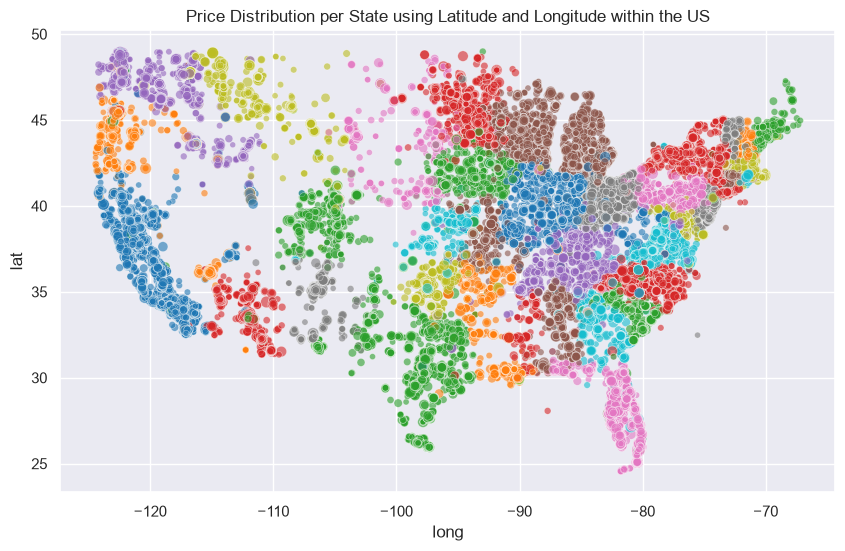

In [293]:
# Box plot of price distribution per state, removing outliers above the 99th percentile and cars priced 0$,
# using latitude and longitude within the US for plotting

us_located_data = price_filtered(data)[(price_filtered(data)["lat"] >= 24.396308) & (price_filtered(data)["lat"] <= 49.384358) & 
                                (price_filtered(data)["long"] >= -125.0) & (price_filtered(data)["long"] <= -66.93457)]

plt.figure(figsize=(10, 6))
sns.scatterplot(x='long', y='lat', hue='state', size='price', data=us_located_data.sample(frac=0.5), palette='tab10', legend=False, alpha=0.6)
plt.title('Price Distribution per State using Latitude and Longitude within the US')
plt.show()

## Mutual information

In [294]:
# Low-count manufacturers grouped into 'Other', low count is defined as less than 10% of the total number of entries
manufacturer_counts = price_filtered(data).groupby('manufacturer').size()
low_count_manufacturers = manufacturer_counts[manufacturer_counts < 0.05 * manufacturer_counts.sum()].index
data_grouped = price_filtered(data).copy()
data_grouped['manufacturer'] = data_grouped['manufacturer'].apply(lambda x: 'Other' if x in low_count_manufacturers else x)

In [295]:
# Mutual Information between features and price

from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

mi_data = price_filtered(data_grouped).drop(columns=['model', 'paint_color', 'size', 'title_status', 'region']).sample(frac=0.5, random_state=42)
X = mi_data.drop(columns='price')
y = mi_data['price']

categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numerical_features = X.select_dtypes(exclude=['object']).columns.tolist()

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_transformed = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()

mutual_info = mutual_info_regression(X_transformed, y, random_state=42)
mutual_info = pd.Series(mutual_info, index=feature_names)
mutual_info = mutual_info.sort_values(ascending=False)

C:\Users\Luka\AppData\Local\Temp\ipykernel_19512\1350034969.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=['object']).columns.tolist()


In [296]:
mutual_info.index

Index(['num__odometer', 'num__long', 'num__lat', 'num__year',
       'cat__transmission_other', 'cat__transmission_automatic',
       'cat__condition_good', 'cat__condition_excellent', 'cat__drive_fwd',
       'cat__cylinders_4 cylinders', 'cat__fuel_gas', 'cat__type_sedan',
       'cat__fuel_other', 'cat__cylinders_6 cylinders', 'cat__drive_4wd',
       'cat__type_pickup', 'cat__fuel_diesel', 'cat__type_truck',
       'cat__cylinders_8 cylinders', 'cat__type_other',
       'cat__manufacturer_Other', 'cat__condition_fair', 'cat__type_SUV',
       'cat__manufacturer_ford', 'cat__type_hatchback', 'cat__drive_rwd',
       'cat__transmission_manual', 'cat__state_wa', 'cat__state_ca',
       'cat__manufacturer_chevrolet', 'cat__condition_like new',
       'cat__state_mt', 'cat__manufacturer_honda', 'cat__state_fl',
       'cat__state_or', 'cat__type_coupe', 'cat__state_mi',
       'cat__manufacturer_toyota', 'cat__type_wagon', 'cat__state_id',
       'cat__state_oh', 'cat__state_tx', 'cat__

C:\Users\Luka\AppData\Local\Temp\ipykernel_19512\198406957.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mutual_info.head(40), y=mutual_info.head(40).index, palette='pastel')


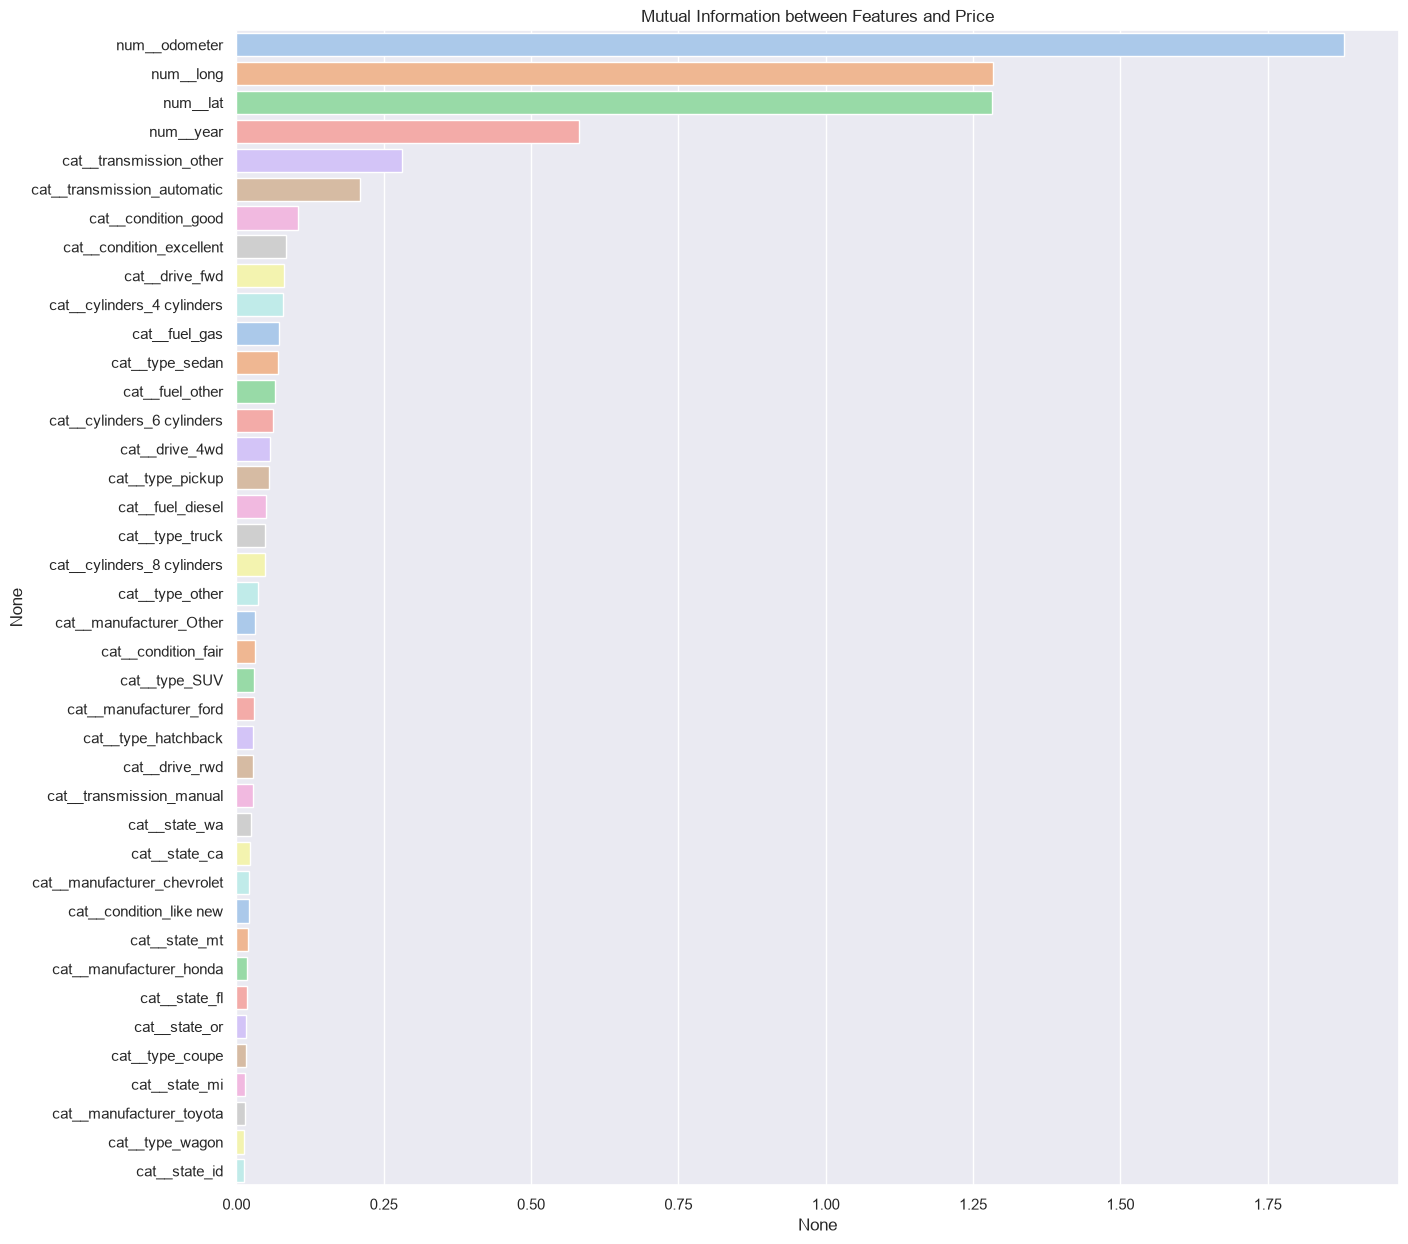

In [297]:
plt.figure(figsize=(15,15))
sns.barplot(x=mutual_info.head(40), y=mutual_info.head(40).index, palette='pastel')
plt.title('Mutual Information between Features and Price')
plt.show()

C:\Users\Luka\AppData\Local\Temp\ipykernel_19512\587308554.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mutual_info.tail(40), y=mutual_info.tail(40).index, palette='pastel')


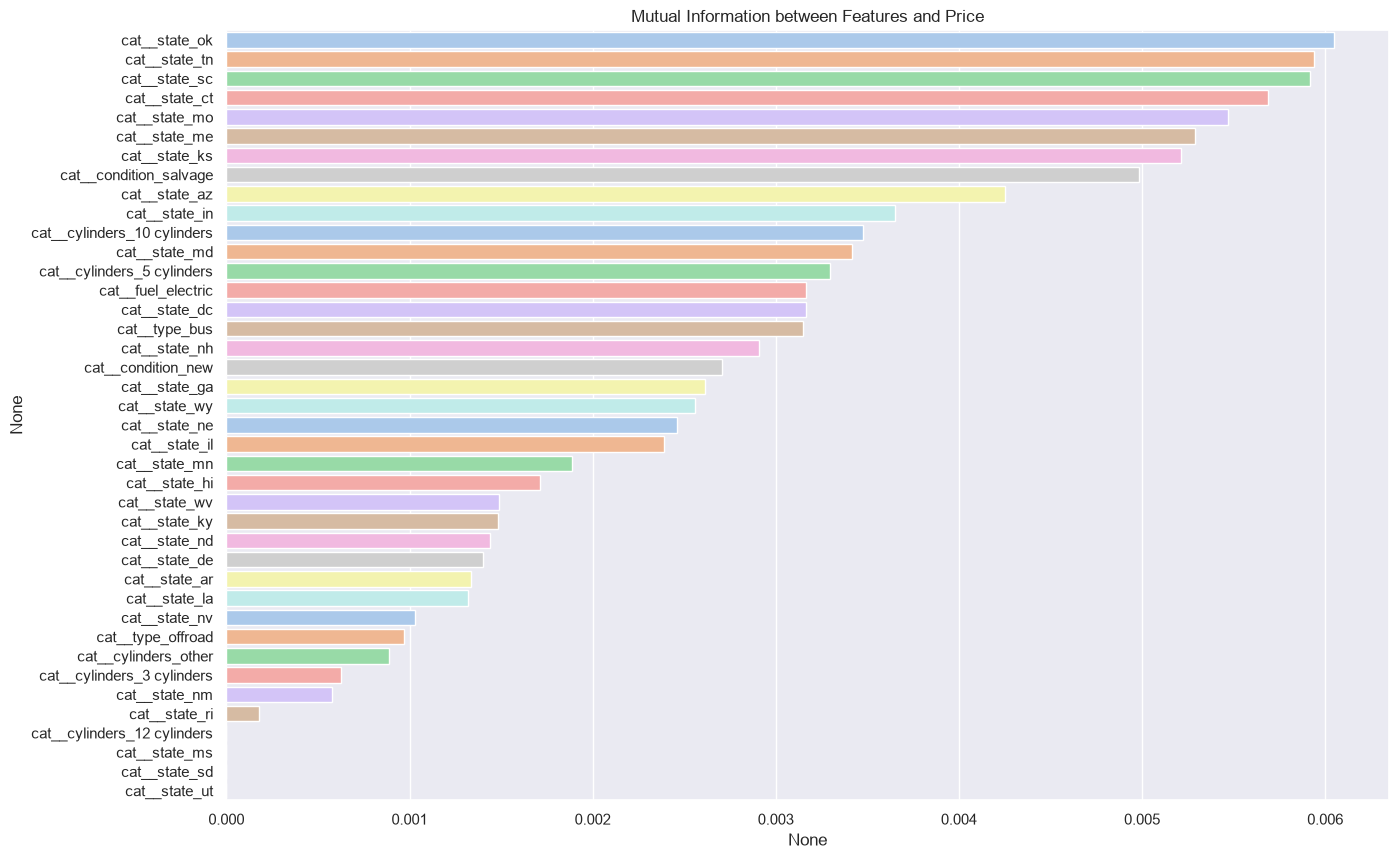

In [298]:
plt.figure(figsize=(15, 10))
sns.barplot(x=mutual_info.tail(40), y=mutual_info.tail(40).index, palette='pastel')
plt.title('Mutual Information between Features and Price')
plt.show()

## EDA Summary — decisions carried to feature engineering/selection

**Target:**
- drop outliers, best to drop up to 10th percentile and above 99th percentile

**Drop:**
- model (30k+ uniques)
- size (70% null, flat across categories)
- paint_color (30% null, flat across categories)
- title_status='lien' rows (leakage) — or drop title_status entirely if imbalance too severe
- cars before year 2000 (heavy skew, low counts, weak relationship)

**Engineer:**
- age = current_year - year
- location_cluster from lat/long (KMeans)
- bucket rare categories into "other"

**Class imbalance:**
- manufacturer, condition, cylinders, gas, transmission, fuel, type
- state (redundancy vs lat/long/region, but better to keep for now)

**Keep as-is:**
- drive, odometer

**Open questions for next notebook:**
- state vs lat/long/region redundancy
- best encoding strategy for region (400 categories)

**Mutual info results:**
- odometer, lat, long, year, transmission, condition, drive, type - STRONG